# CSC 303 — AI Academic Advisor: Model Training

This notebook trains the machine-learning part of my **Academic Advisor System**.
It is meant to run on **Google Colab** (Runtime → Run all).

**What the model does:** given a student's academic profile (CGPA, last semester GPA,
attendance, study hours, assignment completion, carry-over courses and course load),
it predicts the student's **academic standing**:

| Class | Meaning |
|---|---|
| `Excellent` | Performing at First Class level, keep it up |
| `On Track` | Doing fine, small improvements possible |
| `Needs Support` | Warning signs, needs a study plan |
| `At Risk` | Serious risk of probation / poor class of degree |

**Pipeline:** generate dataset → explore → train & compare 3 models → evaluate → save the best one as `advisor_model.pkl` → download it for the Flask web app.

GPA values use the Nigerian **5.0 grading scale**.

In [1]:
# 1. Imports and environment check
import sys, pickle, json
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, ConfusionMatrixDisplay

IN_COLAB = "google.colab" in sys.modules
print("Python:", sys.version.split()[0])
print("scikit-learn:", sklearn.__version__)
print("Running on Google Colab:", IN_COLAB)

Python: 3.13.16
scikit-learn: 1.9.1
Running on Google Colab: False


## 2. Build the dataset

There is no public dataset of my department's student records (and real records would be private),
so I generate a **synthetic but realistic** dataset of 2,000 students. Each feature is drawn from
a sensible range, and the standing label comes from a weighted performance score plus random noise,
so the model has to learn the pattern rather than memorise a formula.

In [2]:
# 2. Generate synthetic student records
RNG_SEED = 303
rng = np.random.default_rng(RNG_SEED)
N = 2000

FEATURES = [
    "cgpa",             # cumulative GPA, 0.0 - 5.0
    "last_gpa",         # last semester GPA, 0.0 - 5.0
    "attendance",       # class attendance, %
    "study_hours",      # personal study hours per week
    "assignment_rate",  # % of assignments submitted
    "carryovers",       # number of failed courses still to clear
    "course_units",     # units registered this semester
]

ability = rng.normal(0, 1, N)  # hidden "ability + habits" factor that links the features

cgpa = np.clip(3.0 + 0.85 * ability + rng.normal(0, 0.35, N), 0.5, 5.0)
last_gpa = np.clip(cgpa + rng.normal(0, 0.45, N), 0.0, 5.0)
attendance = np.clip(75 + 12 * ability + rng.normal(0, 10, N), 20, 100)
study_hours = np.clip(12 + 5 * ability + rng.normal(0, 4, N), 0, 40)
assignment_rate = np.clip(80 + 12 * ability + rng.normal(0, 10, N), 0, 100)
carryovers = np.clip(np.round(rng.poisson(np.exp(-0.9 * ability) * 0.8)), 0, 8)
course_units = np.clip(np.round(rng.normal(22, 3, N)), 12, 30)

df = pd.DataFrame({
    "cgpa": cgpa.round(2),
    "last_gpa": last_gpa.round(2),
    "attendance": attendance.round(1),
    "study_hours": study_hours.round(1),
    "assignment_rate": assignment_rate.round(1),
    "carryovers": carryovers.astype(int),
    "course_units": course_units.astype(int),
})

# Weighted performance score (0-100 range roughly) + noise
score = (
    9.0 * df.cgpa
    + 5.0 * df.last_gpa
    + 0.18 * df.attendance
    + 0.45 * df.study_hours
    + 0.12 * df.assignment_rate
    - 4.0 * df.carryovers
    - 0.35 * np.clip(df.course_units - 24, 0, None)  # overload penalty
    + rng.normal(0, 2.0, N)
)

def label(s):
    if s >= 75: return "Excellent"
    if s >= 61: return "On Track"
    if s >= 48: return "Needs Support"
    return "At Risk"

df["standing"] = score.apply(label)
CLASSES = ["At Risk", "Needs Support", "On Track", "Excellent"]

df.to_csv("student_records.csv", index=False)
print(df.shape)
df.head()

(2000, 8)


,cgpa,last_gpa,attendance,study_hours,assignment_rate,carryovers,course_units,standing
0,2.33,2.75,64.7,8.0,63.2,1,23,Needs Support
1,2.85,1.41,62.6,8.2,62.7,0,24,Needs Support
2,2.40,2.07,50.7,6.5,47.8,0,20,Needs Support
3,3.24,3.19,84.5,12.1,89.5,1,24,On Track
4,2.04,1.31,67.5,9.5,65.5,1,21,At Risk


## 3. Explore the data

standing
At Risk          395
Needs Support    401
On Track         490
Excellent        714
Name: count, dtype: int64


,cgpa,last_gpa,attendance,study_hours,assignment_rate,carryovers,course_units
count,2000.00,2000.00,2000.00,2000.00,2000.00,2000.00,2000.00
mean,2.98,2.98,74.61,11.99,79.04,1.16,21.91
std,0.89,0.99,14.50,6.16,14.34,1.58,2.98
min,0.50,0.00,25.70,0.00,24.00,0.00,12.00
25%,2.38,2.29,64.50,7.80,69.40,0.00,20.00
50%,2.99,2.97,75.00,11.90,79.65,1.00,22.00
75%,3.59,3.70,85.10,16.02,90.12,2.00,24.00
max,5.00,5.00,100.00,35.70,100.00,8.00,30.00


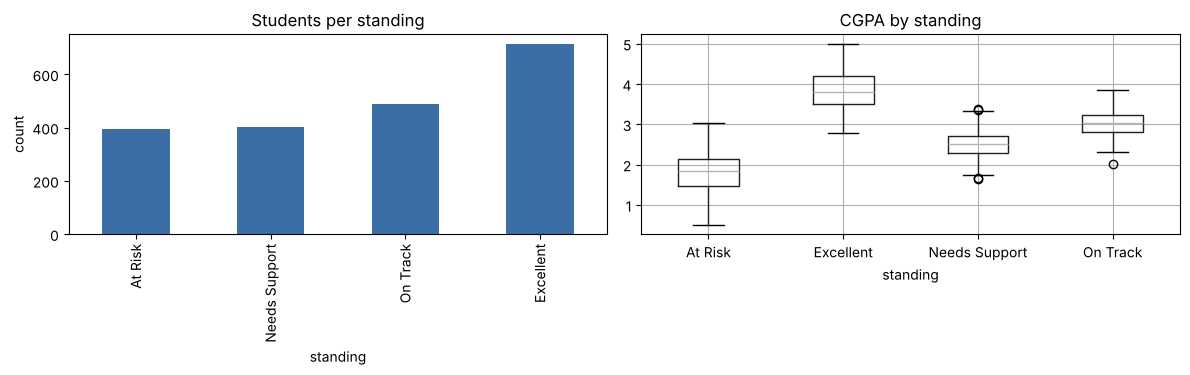

In [3]:
# 3. Quick exploratory data analysis
print(df["standing"].value_counts().reindex(CLASSES))
display(df.describe().round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df["standing"].value_counts().reindex(CLASSES).plot(kind="bar", ax=axes[0], color="#3b6ea5")
axes[0].set_title("Students per standing"); axes[0].set_ylabel("count")
df.boxplot(column="cgpa", by="standing", ax=axes[1], positions=None)
axes[1].set_title("CGPA by standing"); plt.suptitle("")
plt.tight_layout(); plt.show()

## 4. Train and compare models

I split the data 80/20 (stratified), then compare three classifiers with 5-fold cross-validation.
Each model sits inside a scikit-learn `Pipeline` with a `StandardScaler`, so the exact same
preprocessing runs in training and in the web app.

In [4]:
# 4. Train/test split and model comparison
X = df[FEATURES]
y = df["standing"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RNG_SEED
)

candidates = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, random_state=RNG_SEED),
    "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=12, random_state=RNG_SEED),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RNG_SEED)
cv_results = {}
for name, clf in candidates.items():
    pipe = Pipeline([("scaler", StandardScaler()), ("clf", clf)])
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="accuracy")
    cv_results[name] = scores.mean()
    print(f"{name:20s} CV accuracy = {scores.mean():.3f} (+/- {scores.std():.3f})")

best_name = max(cv_results, key=cv_results.get)
print("\nBest model:", best_name)

Logistic Regression  CV accuracy = 0.918 (+/- 0.012)
Decision Tree        CV accuracy = 0.820 (+/- 0.029)


Random Forest        CV accuracy = 0.886 (+/- 0.006)

Best model: Logistic Regression


## 5. Evaluate the best model on the held-out test set

Test accuracy: 0.940

               precision    recall  f1-score   support

      At Risk       0.96      0.92      0.94        79
Needs Support       0.88      0.91      0.90        80
     On Track       0.91      0.94      0.92        98
    Excellent       0.99      0.97      0.98       143

     accuracy                           0.94       400
    macro avg       0.93      0.94      0.93       400
 weighted avg       0.94      0.94      0.94       400



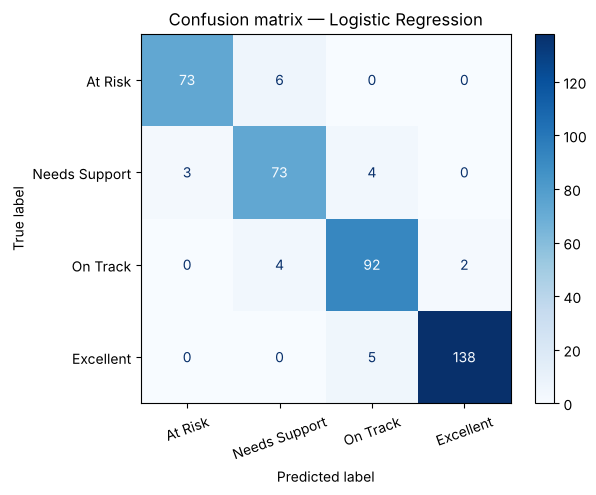

In [5]:
# 5. Fit the best model and evaluate on unseen data
best_pipe = Pipeline([("scaler", StandardScaler()), ("clf", candidates[best_name])])
best_pipe.fit(X_train, y_train)
y_pred = best_pipe.predict(X_test)

test_acc = accuracy_score(y_test, y_pred)
print(f"Test accuracy: {test_acc:.3f}\n")
print(classification_report(y_test, y_pred, labels=CLASSES))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred, labels=CLASSES), display_labels=CLASSES).plot(cmap="Blues")
plt.title(f"Confusion matrix — {best_name}"); plt.xticks(rotation=20); plt.show()

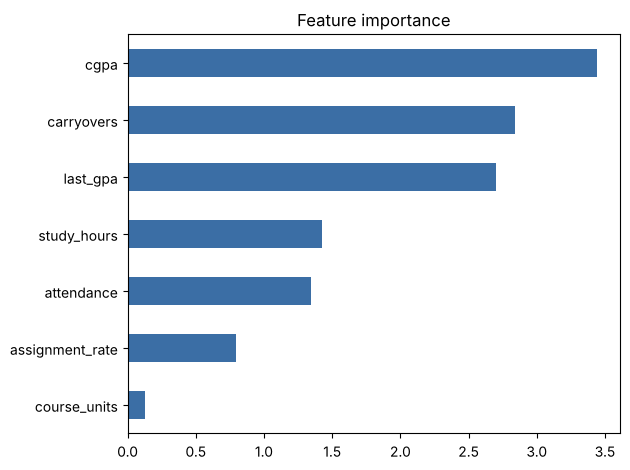

In [6]:
# 6. Which features matter most?
clf = best_pipe.named_steps["clf"]
if hasattr(clf, "feature_importances_"):
    importance = pd.Series(clf.feature_importances_, index=FEATURES)
else:
    importance = pd.Series(np.abs(clf.coef_).mean(axis=0), index=FEATURES)
importance.sort_values().plot(kind="barh", color="#3b6ea5", title="Feature importance")
plt.tight_layout(); plt.show()

## 7. Save the model as a `.pkl` file

I save a small **bundle** (not just the bare model) so the web app knows the feature order,
the class labels, the test accuracy and the scikit-learn version it was trained with.

In [7]:
# 7. Pickle the model bundle
bundle = {
    "model": best_pipe,
    "model_name": best_name,
    "features": FEATURES,
    "classes": CLASSES,
    "test_accuracy": round(float(test_acc), 4),
    "cv_accuracy": {k: round(float(v), 4) for k, v in cv_results.items()},
    "sklearn_version": sklearn.__version__,
    "trained_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "grading_scale": 5.0,
}

with open("advisor_model.pkl", "wb") as f:
    pickle.dump(bundle, f)

print("Saved advisor_model.pkl")
print(json.dumps({k: v for k, v in bundle.items() if k != "model"}, indent=2))

Saved advisor_model.pkl
{
  "model_name": "Logistic Regression",
  "features": [
    "cgpa",
    "last_gpa",
    "attendance",
    "study_hours",
    "assignment_rate",
    "carryovers",
    "course_units"
  ],
  "classes": [
    "At Risk",
    "Needs Support",
    "On Track",
    "Excellent"
  ],
  "test_accuracy": 0.94,
  "cv_accuracy": {
    "Logistic Regression": 0.9181,
    "Decision Tree": 0.82,
    "Random Forest": 0.8856
  },
  "sklearn_version": "1.9.1",
  "trained_at": "2026-10-13T07:25:01+00:00",
  "grading_scale": 5.0
}


In [8]:
# 8. Sanity check: reload the .pkl and predict for a sample student
with open("advisor_model.pkl", "rb") as f:
    loaded = pickle.load(f)

sample = pd.DataFrame([{
    "cgpa": 3.1, "last_gpa": 2.8, "attendance": 65, "study_hours": 8,
    "assignment_rate": 70, "carryovers": 2, "course_units": 26,
}])[loaded["features"]]

pred = loaded["model"].predict(sample)[0]
proba = {c: round(float(p), 3) for c, p in zip(loaded["model"].classes_, loaded["model"].predict_proba(sample)[0])}
print("Predicted standing:", pred)
print("Probabilities:", proba)

Predicted standing: Needs Support
Probabilities: {'At Risk': 0.016, 'Excellent': 0.0, 'Needs Support': 0.871, 'On Track': 0.113}


In [9]:
# 9. Download the .pkl (Colab only) — put it in the repo's model/ folder
if IN_COLAB:
    from google.colab import files
    files.download("advisor_model.pkl")
else:
    print("Not on Colab: advisor_model.pkl is in the current folder.")

Not on Colab: advisor_model.pkl is in the current folder.
